# Logistic Regression Baseline: German Credit
DSE4212/QF4212 Group Project 1

Convention used everywhere: **positive class (1) = default / bad credit**.

- Part 1: Naive baseline (the 7-feature model from the Chapter 6 notebook)
- Part 2: Reference model (untuned logistic regression on the shared pipeline)
- Part 3: Hyperparameter tuning (cross-validation on training data only)
- Part 4: Test-set evaluation and operating points (thresholds)
- Part 5: Interpretation (coefficients and odds ratios)
- Part 6: Save model, probabilities and metrics

In [1]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict

# Find the project root (the folder that contains src/) so `from src...` works
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.preprocessing import make_pipeline, check_inputs   # shared preprocessing (teammate's module)
from src.evaluation import (evaluate, metrics_only, results_table,
                            f1_optimal_threshold, cost_min_threshold,
                            cost_optimal_threshold, bootstrap_auc_ci, RANDOM_STATE)

matplotlib.rcParams.update({'font.size': 12})

# Output folders
OUT = ROOT / "outputs"
for sub in ("models", "predictions", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# Settings
TARGET = "credit_risk"   # 1 = default (bad), 0 = good
FN_COST = 5              # a missed default costs 5x a wrongly rejected good client

## Load Data and inspect
The team's `train.csv` and `test.csv` are used as they are (800 / 200 rows), so every model
in the project is trained and tested on identical rows.

In [2]:
train = pd.read_csv(OUT / "train.csv")
test = pd.read_csv(OUT / "test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (800, 27) | test: (200, 27)


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,...,job,people_liable,telephone,foreign_worker,original_label,credit_risk,gender_group,age_group,log1p_credit_amount,log1p_duration_months
0,1,0 to <200 DM,48,Existing credits paid duly so far,Radio/television,5951,<100 DM,1 to <4 years,2,Female: divorced/separated/married,...,Skilled employee/official,1,No / none,Yes,2,1,Female,<25,8.691483,3.891820
1,2,No checking account,12,Critical account / other credits elsewhere,Education,2096,<100 DM,4 to <7 years,2,Male: single,...,Unskilled resident,2,No / none,Yes,1,0,Male,45-54,7.648263,2.564949
2,3,<0 DM,42,Existing credits paid duly so far,Furniture/equipment,7882,<100 DM,4 to <7 years,2,Male: single,...,Skilled employee/official,2,No / none,Yes,1,0,Male,45-54,8.972464,3.761200
3,4,<0 DM,24,Past repayment delay,New car,4870,<100 DM,1 to <4 years,3,Male: single,...,Skilled employee/official,2,No / none,Yes,2,1,Male,45-54,8.491055,3.218876
4,5,No checking account,36,Existing credits paid duly so far,Education,9055,Unknown / no savings account,1 to <4 years,2,Male: single,...,Unskilled resident,2,Registered in customer name,Yes,1,0,Male,35-44,9.111183,3.610918


In [3]:
# Separate features and target
y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])

print(f"Default rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")   # German Credit has ~30% bad
check_inputs(X_train)   # raises if expected columns are missing

Default rate: train 0.300, test 0.300


## Part 1: Naive baseline (Chapter 6 approach)
In class we fitted a plain `LogisticRegression()` on 7 numeric columns only, with no scaling,
no categorical variables and no tuning. We repeat it here on the **shared** train/test split so
it is directly comparable with everything below.

In [4]:
naive_features = ["log1p_credit_amount", "log1p_duration_months", "installment_rate",
                  "residence_since", "age_years", "existing_credits", "people_liable"]

naive = LogisticRegression(max_iter=1000)
naive.fit(X_train[naive_features], y_train)

res_naive = evaluate(naive, X_test[naive_features], y_test,
                     name="Naive LR (7 numeric features)", fn_cost=FN_COST, report=True)

=== Naive LR (7 numeric features) | threshold = 0.500 ===
AUC 0.6799 | Precision 0.8333 | Recall 0.0833 | F1 0.1515 | Accuracy 0.7200
          pred 0  pred 1
actual 0     139       1
actual 1      55       5
              precision    recall  f1-score   support

           0       0.72      0.99      0.83       140
           1       0.83      0.08      0.15        60

    accuracy                           0.72       200
   macro avg       0.77      0.54      0.49       200
weighted avg       0.75      0.72      0.63       200



**Remark.** Accuracy looks acceptable only because 70% of clients are good: predicting
"good" for everyone already scores 0.70. The recall on defaults and the AUC are the
informative numbers, and both are weak. The remaining parts improve this step by step.

## Part 2: Reference model (untuned logistic regression + shared pipeline)
`make_pipeline` (in `src/preprocessing.py`) one-hot encodes the categorical columns, scales the
numeric ones and adds the engineered flags. The classifier is the team's untuned
`LogisticRegression(max_iter=1000)` (C = 1, L2 penalty).

In [6]:
lr_default = make_pipeline(LogisticRegression(max_iter=1000), scale_numeric=True)
lr_default.fit(X_train, y_train)
res_default = evaluate(lr_default, X_test, y_test, name="LR untuned (C=1, L2)", fn_cost=FN_COST)

=== LR untuned (C=1, L2) | threshold = 0.500 ===
AUC 0.8150 | Precision 0.6809 | Recall 0.5333 | F1 0.5981 | Accuracy 0.7850
          pred 0  pred 1
actual 0     125      15
actual 1      28      32


## Part 3: Hyperparameter tuning (training data only)
`RepeatedStratifiedKFold` (5 folds x 2 repeats) on the training set. The scoring metric is
ROC AUC, which does not depend on a threshold and is not distorted by class imbalance.

Grid: `C` (inverse regularisation strength, 11 log-spaced values) x `l1_ratio`
(0 = ridge, 0.5 = elastic net, 1 = lasso). The SAGA solver supports all three.
Requires scikit-learn >= 1.8.

In [7]:
base = make_pipeline(
    LogisticRegression(solver="saga", l1_ratio=0, max_iter=20000, random_state=RANDOM_STATE),
    scale_numeric=True,
)
param_grid = {
    "classifier__C": np.logspace(-3, 2, 11),
    "classifier__l1_ratio": [0.0, 0.5, 1.0],
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
gs = GridSearchCV(base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gs.fit(X_train, y_train)

best = gs.best_estimator_
cvr = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cv_std = cvr.iloc[0]["std_test_score"]

print(f"Best params: {gs.best_params_}")
print(f"CV AUC: {gs.best_score_:.4f} (+/- {cv_std:.4f})")
cvr[["param_classifier__C", "param_classifier__l1_ratio", "mean_test_score", "std_test_score"]].head(8)

Best params: {'classifier__C': np.float64(0.03162277660168379), 'classifier__l1_ratio': 0.0}
CV AUC: 0.7692 (+/- 0.0338)


,param_classifier__C,param_classifier__l1_ratio,mean_test_score,std_test_score
9,0.031623,0.0,0.769178,0.033816
12,0.100000,0.0,0.768341,0.029836
16,0.316228,0.5,0.765551,0.027610
15,0.316228,0.0,0.763839,0.026690
6,0.010000,0.0,0.761403,0.037001
17,0.316228,1.0,0.760063,0.029626
20,1.000000,1.0,0.758966,0.024447
19,1.000000,0.5,0.758854,0.025057


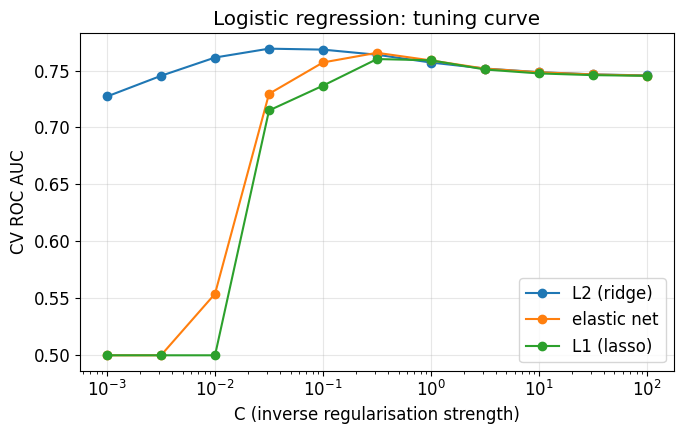

In [8]:
# CV AUC across the grid
fig, ax = plt.subplots(figsize=(7, 4.5))
names = {0.0: "L2 (ridge)", 0.5: "elastic net", 1.0: "L1 (lasso)"}
for l1, g in cvr.groupby("param_classifier__l1_ratio"):
    g = g.sort_values("param_classifier__C")
    ax.plot(g["param_classifier__C"].astype(float), g["mean_test_score"],
            marker="o", label=names[float(l1)])
ax.set_xscale("log")
ax.set_xlabel("C (inverse regularisation strength)")
ax.set_ylabel("CV ROC AUC")
ax.set_title("Logistic regression: tuning curve")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "results/logreg_tuning_curve.png", dpi=200)
plt.show()

**Remark.** Strong regularisation (small C) with lasso or elastic net shrinks everything
to zero and the AUC collapses to 0.5. Ridge is the most stable choice, and the AUC is flat
for moderate to large C, so tuning gives only a small gain over the untuned model.

## Part 4: Test-set evaluation and operating points
The AUC measures *ranking* quality. The classification **threshold** is a separate,
cost-driven decision, so it is chosen from **out-of-fold training predictions**
(never on the test set):

- 0.5, the default
- the F1-optimal threshold
- the cost-optimal threshold, where a missed default costs `FN_COST` times a wrongly rejected good client

In [9]:
# Out-of-fold probabilities on the training set
oof = cross_val_predict(best, X_train, y_train, method="predict_proba",
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))[:, 1]
pd.DataFrame({"index": X_train.index, "y_true": y_train.values, "y_proba": oof}).to_csv(
    OUT / "predictions/logreg_train_oof_proba.csv", index=False)

t_f1 = f1_optimal_threshold(y_train, oof)
t_cost = cost_min_threshold(y_train, oof, cost_fn=FN_COST)
print(f"F1-optimal threshold: {t_f1:.3f} | cost-optimal threshold (FN:FP = {FN_COST}:1): {t_cost:.3f} "
      f"(theory for perfectly calibrated probabilities: {cost_optimal_threshold(FN_COST):.3f})")

F1-optimal threshold: 0.304 | cost-optimal threshold (FN:FP = 5:1): 0.188 (theory for perfectly calibrated probabilities: 0.167)


In [10]:
res_05 = evaluate(best, X_test, y_test, threshold=0.5, name="LR tuned @ 0.5", fn_cost=FN_COST,
                  save_to=str(OUT / "predictions/logreg_test_proba.csv"))
res_f1 = evaluate(best, X_test, y_test, threshold=t_f1, name="LR tuned @ F1-optimal", fn_cost=FN_COST)
res_cost = evaluate(best, X_test, y_test, threshold=t_cost, name="LR tuned @ cost-optimal", fn_cost=FN_COST)

ci = bootstrap_auc_ci(y_test, res_05["y_proba"])
print(f"\nTest AUC = {res_05['auc']:.3f}, 95% bootstrap CI [{ci[0]:.3f}, {ci[1]:.3f}]")

=== LR tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8163 | Precision 0.7692 | Recall 0.3333 | F1 0.4651 | Accuracy 0.7700
          pred 0  pred 1
actual 0     134       6
actual 1      40      20
=== LR tuned @ F1-optimal | threshold = 0.304 ===
AUC 0.8163 | Precision 0.5679 | Recall 0.7667 | F1 0.6525 | Accuracy 0.7550
          pred 0  pred 1
actual 0     105      35
actual 1      14      46
=== LR tuned @ cost-optimal | threshold = 0.188 ===
AUC 0.8163 | Precision 0.4390 | Recall 0.9000 | F1 0.5902 | Accuracy 0.6250
          pred 0  pred 1
actual 0      71      69
actual 1       6      54

Test AUC = 0.816, 95% bootstrap CI [0.749, 0.877]


In [11]:
table = results_table([res_naive, res_default, res_05, res_f1, res_cost], fn_cost=FN_COST)
table.to_csv(OUT / "results/logreg_results_table.csv", index=False)
table

,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,Naive LR (7 numeric features),0.500,0.680,0.833,0.083,0.152,0.720,139/1/55/5,276.0
1,"LR untuned (C=1, L2)",0.500,0.815,0.681,0.533,0.598,0.785,125/15/28/32,155.0
2,LR tuned @ 0.5,0.500,0.816,0.769,0.333,0.465,0.770,134/6/40/20,206.0
3,LR tuned @ F1-optimal,0.304,0.816,0.568,0.767,0.652,0.755,105/35/14/46,105.0
4,LR tuned @ cost-optimal,0.188,0.816,0.439,0.900,0.590,0.625,71/69/6/54,99.0


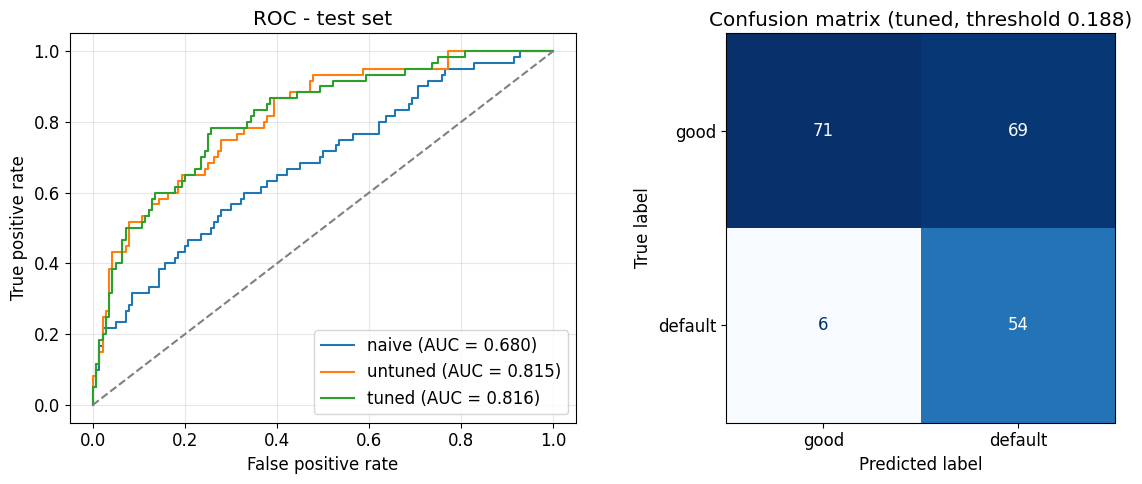

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curves on the test set
for res, label in [(res_naive, "naive"), (res_default, "untuned"), (res_05, "tuned")]:
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    axes[0].plot(fpr, tpr, label=f"{label} (AUC = {res['auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

# Confusion matrix of the tuned model at the cost-optimal threshold
ConfusionMatrixDisplay(res_cost["confusion_matrix"], display_labels=["good", "default"]).plot(
    ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"Confusion matrix (tuned, threshold {t_cost:.3f})")

plt.tight_layout()
plt.savefig(OUT / "results/logreg_roc_confusion.png", dpi=200)
plt.show()

**Remark.** Tuning barely changes the AUC, but the threshold changes the recall on defaults
a lot. Lowering the threshold catches more defaulters at the price of rejecting more good
clients. Which operating point is right depends on the cost ratio, which is the key input
for the business recommendations.

## Part 5: Interpretation (coefficients)
Numeric features are standardised, so their coefficients are the change in log-odds of
default per one standard deviation. One-hot categories and engineered 0/1 flags are not
scaled: their coefficients compare the category with its absence. `odds_ratio = exp(coef)`.

0 of 70 coefficients shrunk exactly to zero


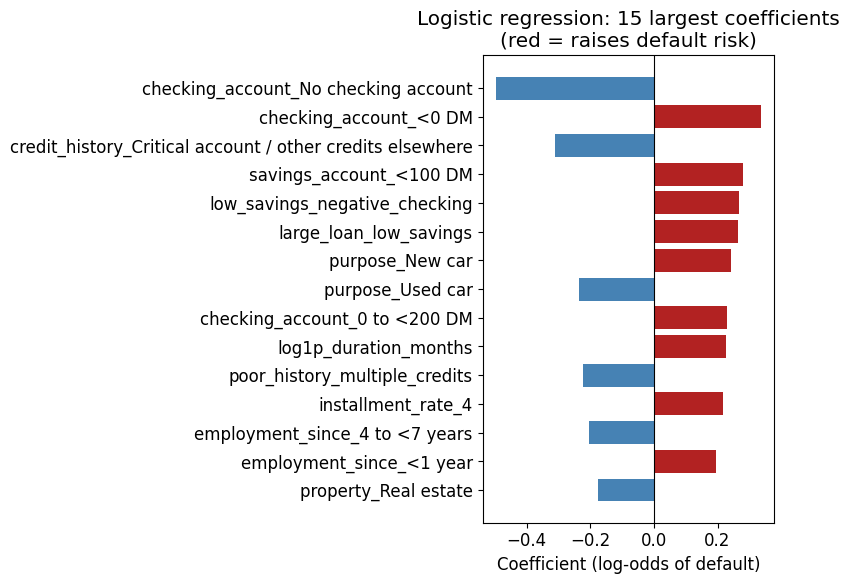

,feature,coef,odds_ratio
0,checking_account_No checking account,-0.496760,0.608499
1,checking_account_<0 DM,0.335792,1.399048
2,credit_history_Critical account / other credit...,-0.309643,0.733709
3,savings_account_<100 DM,0.281442,1.325039
4,low_savings_negative_checking,0.266263,1.305079
5,large_loan_low_savings,0.263116,1.300978
6,purpose_New car,0.241420,1.273055
7,purpose_Used car,-0.236645,0.789271
8,checking_account_0 to <200 DM,0.230355,1.259047
9,log1p_duration_months,0.228104,1.256216


In [13]:
feat_names = [n.split("__", 1)[-1] for n in best.named_steps["preprocessing"].get_feature_names_out()]
coefs = pd.DataFrame({"feature": feat_names, "coef": best.named_steps["classifier"].coef_.ravel()})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.to_csv(OUT / "results/logreg_coefficients.csv", index=False)
print(f"{(coefs['coef'] == 0).sum()} of {len(coefs)} coefficients shrunk exactly to zero")

top = coefs.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, "firebrick", "steelblue"))
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Coefficient (log-odds of default)")
plt.title("Logistic regression: 15 largest coefficients\n(red = raises default risk)")
plt.tight_layout()
plt.savefig(OUT / "results/logreg_coefficients.png", dpi=200)
plt.show()
coefs.head(15)

## Part 6: Save model, probabilities and metrics

In [14]:
joblib.dump(best, OUT / "models/logreg_best.joblib")

summary = {
    "best_params": {k.replace("classifier__", ""): float(v) for k, v in gs.best_params_.items()},
    "cv_auc_mean": float(gs.best_score_), "cv_auc_std": float(cv_std),
    "test_auc_ci95": ci, "fn_cost": FN_COST,
    "thresholds": {"default": 0.5, "f1_opt": t_f1, "cost_opt": t_cost},
    "results": {r["name"]: metrics_only(r)
                for r in (res_naive, res_default, res_05, res_f1, res_cost)},
}
(OUT / "results/logreg_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT)

Saved to c:\Users\linxu\OneDrive - National University of Singapore\DSE4212\DSE4212-Creditscoring\outputs


## Notes for the report

- **For teammates (RF, AdaBoost):** call
  `evaluate(model, X_test, y_test, name=..., save_to="outputs/predictions/<model>_test_proba.csv")`
  so all models produce identical metrics and a probability file that can be overlaid on one ROC plot.
- The test set is small (about 200 customers), so compare models with the AUC confidence interval in mind.
- Thresholds were set on out-of-fold training predictions. The test set was used once, for the final numbers.
- `gender_group` and `age_group` are sensitive attributes. Keep them out of the model inputs
  (check what `make_pipeline` does) and use them only for the optional fairness analysis.